In [1]:
#!pip install pycaret==3.0
#!pip install requests

In [2]:
import pycaret
pycaret.__version__

'3.3.2'

In [3]:
from pycaret.datasets import get_data
data = get_data('insurance')

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [4]:
data

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


In [5]:
data.to_csv('insurance.csv', index=False)

# Experiment 2

In [6]:
from pycaret.regression import *

s2 = setup(data, target = 'charges',
           normalize = True,
           polynomial_features = True,
           bin_numeric_features= ['age', 'bmi'])

,Description,Value
0,Session id,3240
1,Target,charges
2,Target type,Regression
3,Original data shape,"(1338, 7)"
4,Transformed data shape,"(1338, 55)"
5,Transformed train set shape,"(936, 55)"
6,Transformed test set shape,"(402, 55)"
7,Numeric features,3
8,Categorical features,3
9,Preprocess,True


In [7]:
lr = create_model('lr')

,MAE,MSE,RMSE,R2,RMSLE,MAPE
Fold,,,,,,
0,3238.0355,33692787.6739,5804.5489,0.8348,0.5133,0.3239
1,3354.9341,26829386.4169,5179.7091,0.8193,0.4909,0.3852
2,2260.8234,10446140.4856,3232.0490,0.9229,0.3160,0.2739
3,3663.7528,36122592.1099,6010.2073,0.7950,0.4938,0.2918
4,3807.2245,41752497.2227,6461.6172,0.7744,0.4447,0.2844
5,2381.1218,14771485.0846,3843.3690,0.9187,0.3217,0.2410
6,2462.5413,16309812.7074,4038.5409,0.8845,0.3572,0.3203
7,2662.2081,20601896.2235,4538.9312,0.8184,0.3985,0.2957
8,2996.1576,28070962.7532,5298.2037,0.7801,0.4864,0.3022


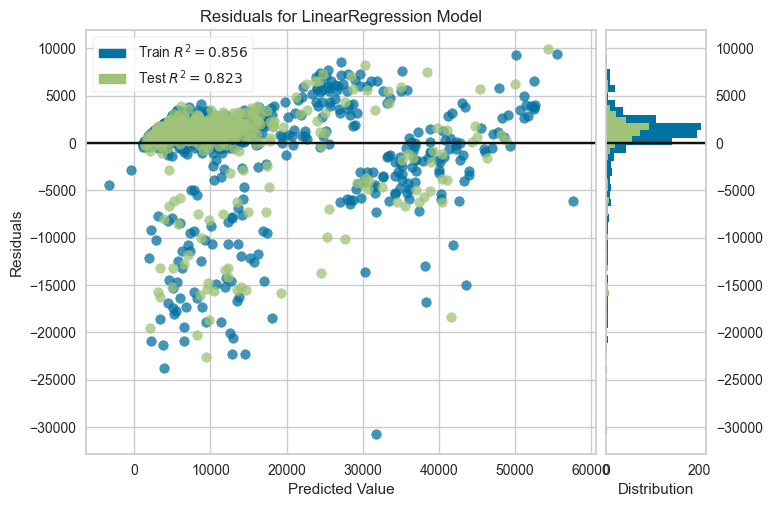

In [8]:
plot_model(lr)

In [9]:
save_model(lr, 'deployment_0')

Transformation Pipeline and Model Successfully Saved


(Pipeline(memory=Memory(location=None),
          steps=[('numerical_imputer',
                  TransformerWrapper(include=['age', 'bmi', 'children'],
                                     transformer=SimpleImputer())),
                 ('categorical_imputer',
                  TransformerWrapper(include=['sex', 'smoker', 'region'],
                                     transformer=SimpleImputer(strategy='most_frequent'))),
                 ('ordinal_encoding',
                  TransformerWrapper(include=['sex', 'smoker'],
                                     transfor...
                                                               use_cat_names=True))),
                 ('polynomial_features',
                  TransformerWrapper(transformer=PolynomialFeatures(include_bias=False))),
                 ('bin_numeric_features',
                  TransformerWrapper(include=['age', 'bmi'],
                                     transformer=KBinsDiscretizer(encode='ordinal',
                 

In [10]:
deployment_0 = load_model('deployment_0')

Transformation Pipeline and Model Successfully Loaded


In [11]:
deployment_0

Pipeline(memory=FastMemory(location=C:\Users\st_cong\AppData\Local\Temp\joblib),
         steps=[('numerical_imputer',
                 TransformerWrapper(include=['age', 'bmi', 'children'],
                                    transformer=SimpleImputer())),
                ('categorical_imputer',
                 TransformerWrapper(include=['sex', 'smoker', 'region'],
                                    transformer=SimpleImputer(strategy='most_frequent'))),
                ('ordinal_encoding',
                 Transforme...
                                                              use_cat_names=True))),
                ('polynomial_features',
                 TransformerWrapper(transformer=PolynomialFeatures(include_bias=False))),
                ('bin_numeric_features',
                 TransformerWrapper(include=['age', 'bmi'],
                                    transformer=KBinsDiscretizer(encode='ordinal',
                                                                 strategy='kmeans'))),
                ('normalize', TransformerWrapper(transformer=StandardScaler())),
                ('trained_model', LinearRegression(n_jobs=-1))])